### EasyOCR

Neither CUDA nor MPS are available - defaulting to CPU. Note: This module is much faster with a GPU.
c:\Users\Cristina\miniconda3\envs\vc_p4\Lib\site-packages\torch\ao\nn\quantized\dynamic\modules\rnn.py:162: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with dtype torch.quint8, torch.qint8, and torch.qint32 are deprecated and will be removed in a future PyTorch release. Please see https://github.com/pytorch/pytorch/issues/184982 for more information. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\quantized\Quantizer.cpp:116.)
  w_ih = torch.quantize_per_tensor(
c:\Users\Cristina\miniconda3\envs\vc_p4\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



Texto: Recuento de puntos (método de victoria opcional)
Probabilidad: 0.74
Contenedor: ((96, 36), (1094, 108))

Texto: Cuando un jugador gana una mano; recibe puntos en función de las cartas que quedan
Probabilidad: 0.87
Contenedor: ((90, 118), (1518, 192))

Texto: en las
Probabilidad: 0.94
Contenedor: ((1513, 155), (1589, 199))

Texto: manos de sus oponentes.
Probabilidad: 0.81
Contenedor: ((94, 176), (528, 226))

Texto: Las cartas se valoran de la siguiente manera:
Probabilidad: 0.85
Contenedor: ((86, 250), (850, 306))

Texto: Cartas del 1al 9
Probabilidad: 1.00
Contenedor: ((236, 328), (516, 376))

Texto: Su valor numérico
Probabilidad: 1.00
Contenedor: ((990, 338), (1304, 386))

Texto: Roba una
Probabilidad: 0.77
Contenedor: ((231, 391), (403, 435))

Texto: 10 puntos
Probabilidad: 1.00
Contenedor: ((994, 398), (1175, 450))

Texto: Roba cinco; Cambio de sentido
Probabilidad: 0.84
Contenedor: ((228, 450), (774, 500))

Texto: Pierde el turno; Flip
Probabilidad: 0.53
Contenedor: ((226

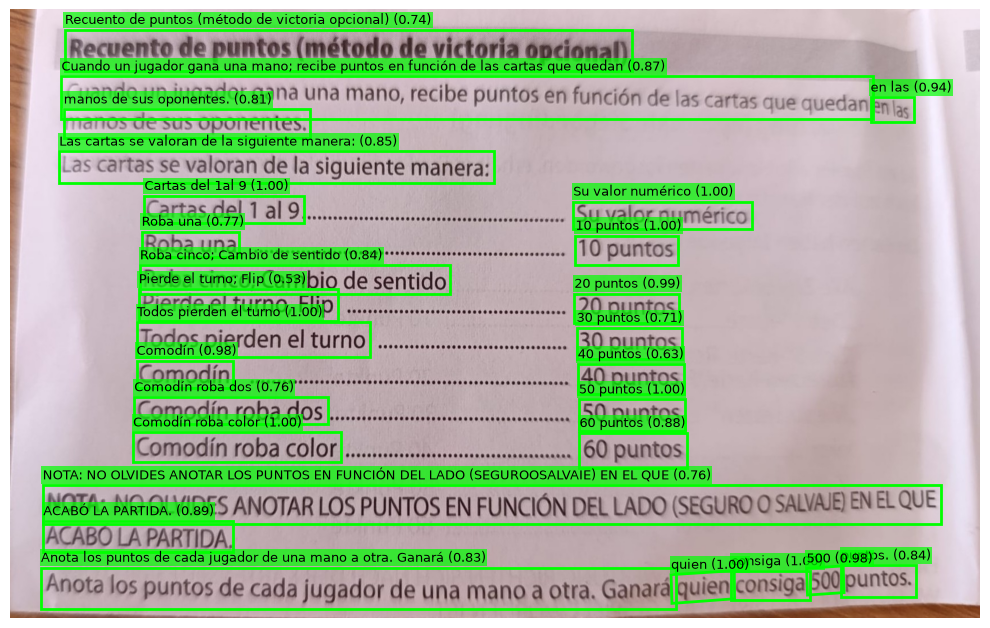

In [1]:
import easyocr
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Carga del modelo de lengua
reader = easyocr.Reader(['es'])
path_image = 'Test.jpg'

# Reconocimiento de una imagen
res = reader.readtext(path_image)

#Con restricción de caracteres reconocibles
#result = reader.readtext(path_image, allowlist ='0123456789')

# Preparar la figura con la imagen
img = plt.imread(path_image)
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img)
ax.axis('off')

for (bbox, text, prob) in res:
    (top_left, top_right, bottom_right, bottom_left) = bbox
    print(f'\nTexto: {text}\nProbabilidad: {prob:.2f}\n'
          f'Contenedor: {tuple(map(int, top_left)), tuple(map(int, bottom_right))}')

    # Recuadro alrededor del texto detectado
    ax.add_patch(patches.Polygon(bbox, closed=True, fill=False,
                                 edgecolor='lime', linewidth=2))

    # Texto reconocido, justo encima del recuadro
    ax.text(top_left[0], top_left[1] - 5, f'{text} ({prob:.2f})',
            color='black', fontsize=9, va='bottom',
            bbox=dict(facecolor='lime', alpha=0.7, pad=1, edgecolor='none'))

plt.tight_layout()
plt.savefig(path_image.replace('.jpg', '_output_Easy_OCR.jpg'), dpi=300, bbox_inches='tight')
plt.show()

### Tesseract

['eng', 'osd', 'spa']
Recuento de puntos (método de victoria opcional)

cuando un jugador gana una mano, recibe puntos en función de las cartas que quedan enja;
manos de sus oponentes.

Las cartas se valoran de la siguiente manera:

Cartas del 1 al 9 eo Su valor numérico
Roba una -—20 a TN bisernacarao 10 puntos

Roba cinco, Cambio de sentido

Pierde el tuma Elp: U 20 puntos

Todos pierden el turno .............r=.esesnceon 30 puntos
Comodiín R A 40 puntos
Comodiín roba dos - 1nDIR NE eee ea 50 puntos
Comodiín roba colOR 1a iic annc 60 puntos

NOTA: NO OLVIDES ANOTAR LOS PUNTOS EN FUNCIÓN DEL LADO (SEGURO O SALVAJE) EN EL QUE
ACABÓ LA PARTIDA.

Anota los puntos de cada jugador de una mano a otra. Ganará quien consiga 500 puntos.

Texto: Recuento (93.00%)
Contenedor: (105, 52, 287, 86)
Texto: de (93.00%)
Contenedor: (296, 47, 345, 86)
Texto: puntos (93.00%)
Contenedor: (355, 49, 494, 95)
Texto: (método (92.00%)
Contenedor: (503, 44, 674, 93)
Texto: de (93.00%)
Contenedor: (685, 46, 733,

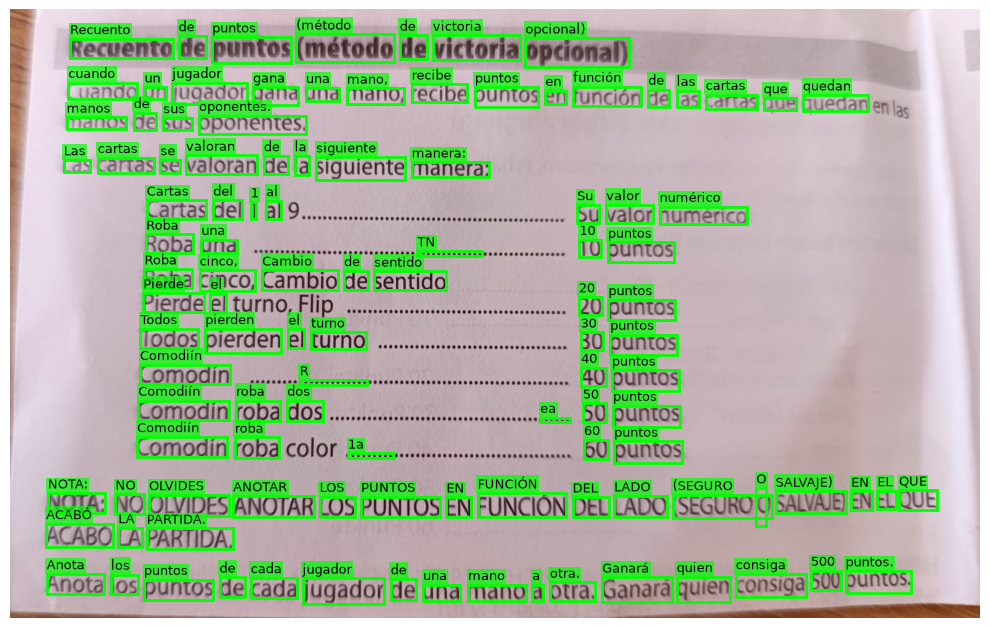

In [2]:

# Tesseract
import cv2
import pytesseract
from pytesseract import Output
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Si la ruta de Tesseract no está en el PATH, ruta al ejecutable
pytesseract.pytesseract.tesseract_cmd = r'C:/Program Files/Tesseract-OCR/tesseract'

#Lenguajes disponibles
print(pytesseract.get_languages(config=''))

path_image = 'Test.jpg'
img = cv2.imread(path_image)

if img is not None:
    # Convierte a RGB antes de procesar
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Texto completo
    print(pytesseract.image_to_string(img_rgb, lang='spa'))

    # Texto y localización de cada palabra
    d = pytesseract.image_to_data(img_rgb, lang='spa', output_type=Output.DICT)

    # Preparar la figura con la imagen
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(img_rgb)
    ax.axis('off')

    n_boxes = len(d['text'])
    for i in range(n_boxes):
        text = d['text'][i].strip()
        conf = float(d['conf'][i])

        # Ignorar detecciones vacías o poco fiables
        if conf > 30 and text:
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])

            print(f'Texto: {text} ({conf:.2f}%)\nContenedor: {x, y, x + w, y + h}')

            # Recuadro alrededor de la palabra
            ax.add_patch(patches.Rectangle((x, y), w, h, fill=False,
                                           edgecolor='lime', linewidth=2))

            # Palabra reconocida, justo encima del recuadro
            ax.text(x, y - 3, text, color='black', fontsize=9, va='bottom',
                    bbox=dict(facecolor='lime', alpha=0.7, pad=1, edgecolor='none'))

    plt.tight_layout()
    plt.savefig(path_image.replace('.jpg', '_output_Tesseract.jpg'), dpi=200, bbox_inches='tight')  # guarda el resultado
    plt.show()

else:
    print('Error de imagen')

### PaddleOCR

In [2]:
# https://github.com/baidu/Unlimited-OCR
import os
import torch
from transformers import AutoModel, AutoTokenizer

# Para que funcione con respecto al de SmolVLM.

# pip install addict
# pip install einops
# pip install easydict
# pip install transformers==4.57.1
 

# Aparentemente tienen llamadas a cuda en el proceso de inferencia, por lo que si no tenemos GPU falla.
# Vamos a hacer que esas llamadas sean no-ops si no hay GPU disponible. 
if not torch.cuda.is_available():
    torch.Tensor.cuda = lambda self, *a, **k: self
    torch.nn.Module.cuda = lambda self, *a, **k: self
    
model_name = 'baidu/Unlimited-OCR'
path_image = 'Test.jpg'
tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModel.from_pretrained(
    model_name,
    trust_remote_code=True,
    use_safetensors=True,
    torch_dtype=torch.bfloat16,
)
model = model.eval().cuda()

# ── Single image supports two configs: gundam or base ──
# gundam: base_size=1024, image_size=640, crop_mode=True
# base: base_size=1024, image_size=1024, crop_mode=False
model.infer(
    tokenizer,
    prompt='<image>document parsing.',
    image_file=path_image,
    output_path=path_image.replace('.jpg', '_output_Unlimited'),
    base_size=1024, image_size=640, crop_mode=True,
    max_length=32768,
    no_repeat_ngram_size=35, ngram_window=128,
    save_results=True,
)


c:\Users\Cristina\miniconda3\envs\vc_p4\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Cristina\.cache\huggingface\hub\models--baidu--Unlimited-OCR. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
A new version of the following files was downloaded from https://huggingface.co/baidu/Unlimited-OCR:
- con

<|det|>title [56, 38, 641, 98]<|/det|>Recuento de puntos (método de victoria opcional)
<|det|>text [48, 113, 930, 208]<|/det|>Cuando un jugador gana una mano, recibe puntos en función de las cartas que quedan en las manos de sus oponentes.
<|det|>text [47, 233, 497, 283]<|/det|>Las cartas se valoran de la siguiente manera:
<|det|>text [134, 306, 764, 358]<|/det|>Cartas del 1 al 9.... Su valor numérico
<|det|>text [134, 363, 686, 414]<|/det|>Roba una 10 puntos
<|det|>text [134, 420, 453, 468]<|/det|>Roba cinco, Cambio de sentido
<|det|>text [134, 468, 686, 513]<|/det|>Pierde el turno, Flip 20 puntos
<|det|>text [131, 520, 688, 568]<|/det|>Todos pierden el turno 30 puntos
<|det|>text [131, 577, 692, 628]<|/det|>Comodín 40 puntos
<|det|>text [129, 636, 692, 686]<|/det|>Comodín roba dos 50 puntos
<|det|>text [129, 696, 695, 746]<|/det|>Comodín roba color 60 puntos
<|det|>text [30, 787, 959, 894]<|/det|>NOTA: NO OLVIDES ANOTAR LOS PUNTOS EN FUNCIÓN DEL LADO (SEGURO O SALVAJE) EN EL QUE ACAB

image: 0it [00:00, ?it/s]
other: 100%|██████████| 13/13 [00:00<00:00, 12997.84it/s]


### SmolVLM

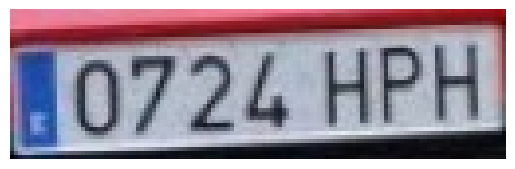

User:<row_1_col_1><row_1_col_2><row_1_col_3><row_1_col_4>
<row_2_col_1><row_2_col_2><row_2_col_3><row_2_col_4>

<global-img>Can you give me the text in the license plate of the image?
Assistant: 0724HPH


In [ ]:
from transformers import AutoProcessor, AutoModelForImageTextToText
import torch
Device = "cpu"  # or "cpu"

processor = AutoProcessor.from_pretrained("HuggingFaceTB/SmolVLM-Instruct")
model = AutoModelForImageTextToText.from_pretrained("HuggingFaceTB/SmolVLM-Instruct",
                                                dtype=torch.bfloat16,
                                                _attn_implementation="flash_attention_2" if Device == "cuda" else "eager").to(Device)

from PIL import Image
from transformers.image_utils import load_image
from matplotlib import pyplot as plt

# Load images

image_1 = Image.open('matricula.jpg')
# Create input messages
messages = [
    {
        "role": "user",
        "content": [
            {"type": "image"},
            {"type": "text", "text": "Can you give me the text in the license plate of the image?"}
        ]
    },
]

# Prepare inputs
prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
inputs = processor(text=prompt, images=[image_1], return_tensors="pt")
inputs = inputs.to(Device)

generated_ids = model.generate(**inputs, max_new_tokens=10)
generated_texts = processor.batch_decode(
    generated_ids,
    skip_special_tokens=True,
)

plt.imshow(image_1)
plt.axis('off')
plt.show()
print(generated_texts[0])